# Prototype V1: Semantic Segmentation model
Modelling for green surface detection via NDVI mask and building mask raster calculations. The actual raster calculations are to be run in an additional Jupyter notebook (raster_calculations.ipynb):  
- Building mask: Rasterizing the vector layer of building footprints
- Vegetation mask: Creating a mask based on a NDVI threshold (still need to research on the optimal threshold for this !!!!)  
- Multiplication Building mask * vegetation mask = only vegetation on buildings  
- Addition only vegetation on buildings mask + building mask  

Training data is also created in another Jupyter notebook (i ran it in colab bc my local computer was overwhelmed and the Kernel kept crashing down...).
This notebook is the prototype running only on a subset from the originally chosen 1km x 1km tile.  

So please check beforehand, that the correct training data is created!

----
#### Overall Idea/Concept
Input: Aerial vexcel imagery  
Labels: Combined raster of building and vegetation mask  
Output: a pixel-wise map of green roofs/vegetated roof areas  

---
#### Current possible limitations *(still need to be checked !!!)*
- overhaning trees  
- slight raster alignment errors  
=> how will i deal with this?

#### 0) Colab setup and library loading
Don't forget to first connect to T4 (faster running CPU ?) Important to run those three coding cells for running the entire model in Colab !  
First step with pip install often takes a while to setup, be patient...  
When mounting Google Drive, connect to your Google drive with the 3rd code cell, you might need to log into your Google account and allow to access Colab.

In [2]:
# Install geospatial libraries
%pip install -q requests geopandas pillow rasterio rioxarray geoai-py leafmap matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# loading all required libraries
from pathlib import Path
import geoai
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import geopandas as gpd
import rasterio
from rasterio.windows import Window
import numpy as np

In [4]:
# Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

# Change project folder/adapt path
DATA_DIR = Path("/content/drive/MyDrive")

Mounted at /content/drive


---
The following workflow is based on the one proposed in the Gitbook from SDS320 L07 Semantic Segmentation - Binary Segmentation Workflow.
### 1) Loading and Inspecting data
Must first define the training data paths and then inspect their info....

In [5]:
# define path !!!!!!!
# need to run the generate training data notebook first to generate the training data
train_ortho = DATA_DIR / "SDS320" / "data" / "training" / "images"
train_mask = DATA_DIR / "SDS320" / "data" / "training" / "labels"

output_path = "../models/"

In [6]:
# Inspect one ortho raster tile
geoai.print_raster_info(train_ortho / "tile_000001.tif", show_preview=False)

===== RASTER INFORMATION: /content/drive/MyDrive/SDS320/data/training/images/tile_000001.tif =====
Driver: GTiff
Dimensions: 512 x 512 pixels
Number of bands: 4
Data type: uint8
Coordinate Reference System: EPSG:2056
Georeferenced Bounds: BoundingBox(left=2666278.8499999996, bottom=1210711.55, right=2666317.2499999995, top=1210749.95)
Pixel Resolution: 0.07, 0.07
NoData Value: None
----- Band Statistics -----
Band 1:
  Min: 14.00
  Max: 236.00
  Mean: 120.34
  Std Dev: 52.67
Band 2:
  Min: 25.00
  Max: 240.00
  Mean: 126.69
  Std Dev: 56.12
Band 3:
  Min: 18.00
  Max: 241.00
  Mean: 126.47
  Std Dev: 63.13
Band 4:
  Min: 29.00
  Max: 245.00
  Mean: 156.69
  Std Dev: 43.11


In [7]:
# Inspect one mask raster tile
geoai.print_raster_info(train_mask / "tile_000001.tif", show_preview=False)

===== RASTER INFORMATION: /content/drive/MyDrive/SDS320/data/training/labels/tile_000001.tif =====
Driver: GTiff
Dimensions: 512 x 512 pixels
Number of bands: 1
Data type: uint8
Coordinate Reference System: EPSG:2056
Georeferenced Bounds: BoundingBox(left=2666278.8499999996, bottom=1210711.55, right=2666317.2499999995, top=1210749.95)
Pixel Resolution: 0.07, 0.07
NoData Value: None
----- Band Statistics -----
Band 1:
  Min: 0.00
  Max: 2.00
  Mean: 0.02
  Std Dev: 0.14


In [8]:
# Check Class balance of entire training mask
### Should only include 0 = background; 1 = building without vegetation; 2 = building with vegetation
mask_path = DATA_DIR / "SDS320" / "data" / "processed" / "mask_subset_center01.tif"

with rasterio.open(mask_path) as src:
    mask = src.read(1, masked=True)

valid_pixels = mask.compressed()
unique, counts = np.unique(valid_pixels, return_counts=True)
total = valid_pixels.size

print(f"Unique classes ({len(unique)}): {unique}")
for u, c in zip(unique, counts):
    print(f"Class {u}: {c:,} pixels ({100 * c / total:.2f}%)")

Unique classes (3): [0 1 2]
Class 0: 29,867,433 pixels (67.20%)
Class 1: 13,796,805 pixels (31.04%)
Class 2: 784,651 pixels (1.77%)


Notes after checking data characteristics: Seems in order (but didn't check visually, still need to do that...). Also very small amount of vegetation detected on buildings/roofs, wonder whether the model will actually be able to detect this...

---
### 2) Training U-Net semantic segmentation model
Based on examples from the Gibook Chapter L07  

This is probably the step i'll need to adjust the most. But as an initial step, i'll just try running it with a very small amount of epochs and a small batch size to see how it looks like.

In [9]:
# Defining a consistent legend for multiclass segmentation
### for now only [0 1 2], maybe later also categorize different subtypes of green roofing like in STDL paper
### For that, adjust this cell then

### Evtl unnötig weil eh nur 3 Klassen....
### Evtl noch L7.7 E. Look at both image-label pairs code hinhzufügen ???
CLASS_NAMES = {
    0: "Background",
    1: "Building",
    2: "Building with vegetated roof"
}

CLASS_COLORS = {
    0: "#000000",
    1: "#BDBDBB",
    2: "#048209"
}

class_ids = sorted(CLASS_NAMES)
assert set(CLASS_COLORS) == set(class_ids), "Every class must have a color."

LC_CMAP = ListedColormap([CLASS_COLORS[i] for i in class_ids])
class_ids_array = np.asarray(class_ids)
class_boundaries = np.r_[
    class_ids_array[0] - 0.5,
    (class_ids_array[:-1] + class_ids_array[1:]) / 2,
    class_ids_array[-1] + 0.5,
]
LC_NORM = BoundaryNorm(class_boundaries, LC_CMAP.N)
LEGEND = [
    Patch(facecolor=CLASS_COLORS[i], edgecolor="gray", label=f"{i}: {CLASS_NAMES[i]}")
    for i in class_ids
]

# Check that the class mapping matches the values in the raster
with rasterio.open(mask_path) as src:
    raster_classes = np.unique(src.read(1, masked=True).compressed())

assert np.array_equal(raster_classes, class_ids_array), (
    f"Raster classes {raster_classes.tolist()} do not match palette classes {class_ids}."
)
print(f"Class mapping check passed: {raster_classes.tolist()}")

Class mapping check passed: [0, 1, 2]


In [10]:
# Train U-Net model
### !! For quick "sanity check", run this with a smaller amount of epochs and batch size
##### e.g. 2 each; full training with batch_size = 8 and num_epochs = 20 to 50

geoai.train_segmentation_model(
    images_dir=train_ortho,
    labels_dir=train_mask,
    output_dir=f"{output_path}/unet_model",
    architecture="unet", # model architecture
    encoder_name="resnet34", # Encoder choice
    encoder_weights="imagenet", # Decoder choice
    num_channels=4, # RGB + NIR
    num_classes=3, # background, building, building with vegetation
    batch_size=8,
    num_epochs=20,
    learning_rate=0.001,
    val_split=0.2, # randomly selects 20% of the training data as validation
)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

!!! vAL_SPLIT MIGHT BE DISADVANTAGEOUS ????

---
### 3) Model Evaluation
Plot training and validation loss alongside IoU (Intersection of Union), F1-score (Combines precision and recall), precision (Proportion of predicted positives that are correct), recall (Proportion of reference positives that the model successfully finds) over training epochs and prints short summary.  
Should show both loss curves decreasing together, growing gap would be sign of overfitting.

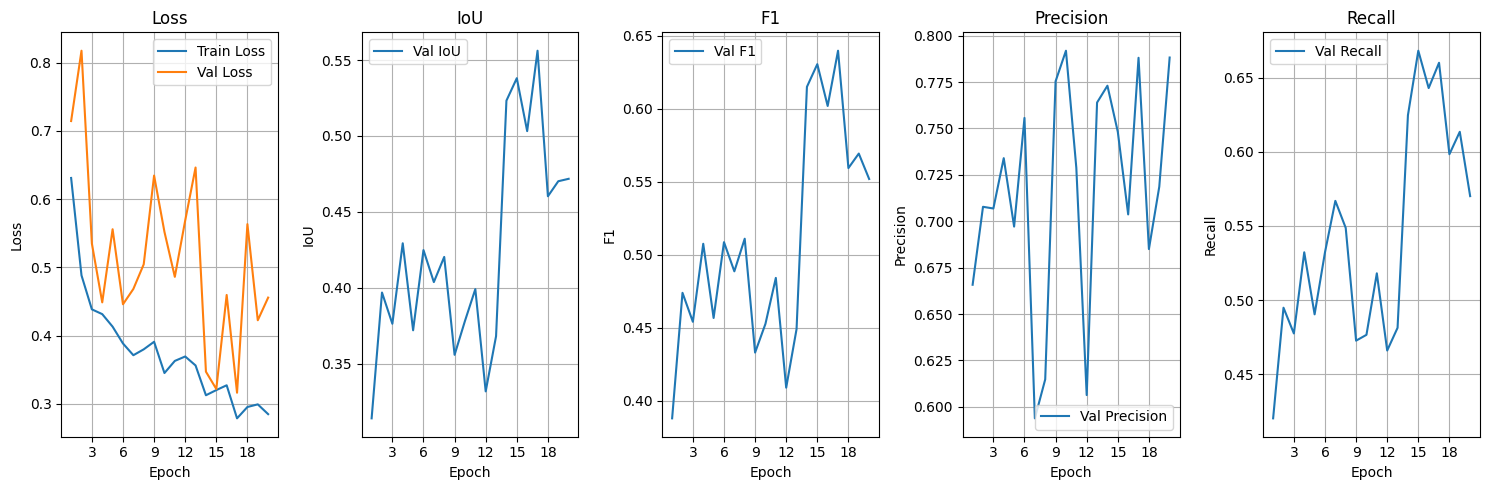

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,0.631179,0.714588,0.313933,0.388105,0.665785,0.420264
1,2,0.488441,0.817651,0.396820,0.473998,0.707803,0.494871
2,3,0.438639,0.535119,0.376236,0.454171,0.706883,0.477508
3,4,0.431636,0.448882,0.429273,0.507556,0.734025,0.532227
4,5,0.413276,0.556016,0.371944,0.456790,0.697139,0.490399
5,6,0.388633,0.446097,0.424799,0.508657,0.755692,0.532186
6,7,0.371428,0.468488,0.403700,0.488702,0.593794,0.566919
7,8,0.380038,0.504607,0.420290,0.511030,0.614783,0.548693
8,9,0.391133,0.634667,0.355774,0.433106,0.775446,0.472648
9,10,0.345321,0.552159,0.378092,0.452778,0.791918,0.476582


In [11]:
# Evaluate Model, inspect training
geoai.plot_performance_metrics(
    history_path=f"{output_path}/unet_model/training_history.pth",
    figsize=(15, 5),
)

---
### 4) Run inference
So before in the training step, we created the model, trained it and got the "best model" as an output. Now the inference step uses this "best model" to make predictions about a new raster. The training step should be done on a specific area/training data set. In contrast to that, the inference step should be run on a spatially separated area !  

State 22/11:   NEED TO DEFINE MY TEST AND VALIDATION AREA (AND IF NEEDED REQUEST NEWLY FROM VEXCEL)
the Test and validation area should be smaller than the test area (data split strategy e.g.)

In [ ]:
# Run inference on test raster
masks_path = "buildingsgreen_prediction.tif" # Final prediction raster created by the model
probability_path = "buildingsgreen_probabilities.tif" # Stores the model confidence
model_path = f"{output_path}/unet_model/best_model.pth"

geoai.semantic_segmentation(
    input_path=test_raster_path, # NEED A NEW RASTER FOR THIS?
    output_path=masks_path,
    model_path=model_path,
    architecture="unet",
    encoder_name="resnet34",
    num_channels=4, # RGB + NIR
    num_classes=3, # background, buildings, buildings with vegetation
    window_size=512, # equals the window size from the semantic training data notebook
    overlap=384, # equals the stride size from the semantic training data notebook
    batch_size=4,
    probability_path=probability_path,
)

---
### 5) Inspect mask and Uncertainty
This is simply a visualizing step where we try to display the predicted building mask over the original imagery.

In [ ]:
# Inspect masks and ucertainty
geoai.view_raster(
    masks_path,
    nodata=0,
    colormap="binary",
    basemap=test_raster_path,
)

In [ ]:
geoai.view_raster(
    probability_path,
    indexes=[2],
    basemap=test_raster_path,
)

---
### 6) Post-adjustment
Here we try to vectorize the output raster predictions.

In [ ]:
# Vectorize and filter predictions
output_vector_path = "marly_buildings_prediction.geojson"

gdf = geoai.orthogonalize(
    masks_path,
    output_vector_path,
    epsilon=2,
)

gdf_props = geoai.add_geometric_properties(gdf, area_unit="m2", length_unit="m")
gdf_filtered = gdf_props[(gdf_props["area_m2"] > 10)]

geoai.create_split_map(
    left_layer=gdf_filtered,
    right_layer=test_raster_path,
    left_args={"style": {"color": "red", "fillOpacity": 0.2}},
    basemap=test_raster_path,
)